# Dark energy from gravitational waves and supernovae

**This is the full tutorial of `bright_cosmology`.** It runs the whole analysis, from the mock data to the reconstruction of dark energy:

| section | what it does |
|---|---|
| 0 | setup |
| 1 | choose the **fiducial cosmology**: the one assumed to be true when the mock data are made |
| 2 | read the **catalog** of neutron-star mergers and give each one a distance |
| 3 | run **GWFish**: how well does the Einstein Telescope measure each merger? |
| 4 | get the probability density of the **distance** of each merger, and inspect it |
| 5 | make mock **supernovae** in the same cosmology |
| 6 | the **Gaussian process** that describes dark energy |
| 7 | the **likelihood**, what it needs, and the sampling (MCMC) |
| 8 | **results**: parameters, dark-energy density and expansion rate |
| appendix | how the $H(z)$ points are obtained |

Two cases are analysed, both in the same fiducial cosmology (PEDE):

- **ET Δ**: gravitational waves only, seen by the Einstein Telescope (ET) in its triangular (Δ) design;
- **ET Δ + Pantheon+**: the same, plus supernovae.

The events are **bright sirens**: mergers of two neutron stars seen both in gravitational waves (GW), which give the *luminosity distance* $d_L$ (the distance inferred from how faint the source appears), and as short gamma-ray bursts (GRB), whose host galaxy gives the *redshift* $z$ (how much the Universe has expanded since).

**Running time:** 15-30 minutes on 4 cores. Results are stored on disk and reused the next time; set `REDO = True` to recompute them.

## 0. Setup

Longer technical functions are in `code/gp_tools.py`, with explanations.

In [1]:
# Move to the root folder of the repo, so that all the paths below work
import os
import sys
from pathlib import Path

while not Path("pyproject.toml").exists():
    if Path.cwd() == Path.cwd().parent:
        raise RuntimeError("Open this notebook from inside the bright_cosmology repo")
    os.chdir("..")

# Use one thread: the MCMC chains already run in parallel
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"

# Make the code of the repo importable
sys.path.insert(0, str(Path.cwd()))
sys.path.insert(0, str(Path.cwd() / "code"))

In [2]:
import warnings
warnings.filterwarnings("ignore")

import dill                                          # to read the .pkl files
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from classy import Class                             # CLASS, the cosmology code
from IPython.utils.capture import capture_output     # hides the long printouts of some steps

import gp_tools
import read_input

In [3]:
# Options of this notebook
REDO = False            # True: recompute also the results that are already on disk
SEED = 43               # seed of the random numbers
N_CHAINS = 4            # number of MCMC chains run in parallel
RMINUS1_STOP = 0.01     # when to stop the MCMC (explained in section 7)

# The two cases: names printed by the notebook, labels and colours in the plots
RUNS = ["ET-delta", "PantheonPlus-ET-delta"]
NAME = {"ET-delta": "ET Δ", "PantheonPlus-ET-delta": "ET Δ + Pantheon+"}
LABEL = {"ET-delta": r"ET $\Delta$", "PantheonPlus-ET-delta": r"ET $\Delta$ + Pantheon+"}
COLOR = {"ET-delta": "#eb6834", "PantheonPlus-ET-delta": "#2a78d6"}
GREY = "#555555"

gp_tools.set_plot_style()

## 1. Fiducial cosmology

In a flat universe the expansion rate is

$$H^2(z) = H_0^2\left[\Omega_m (1+z)^3 + (1-\Omega_m)\, f_{\rm DE}(z)\right],\qquad f_{\rm DE}(z) = \frac{\rho_{\rm DE}(z)}{\rho_{\rm DE}(0)},$$

where $H_0$ is the expansion rate today, $\Omega_m$ the fraction of matter today, and $\rho_{\rm DE}$ the density of dark energy. **$f_{\rm DE}(z)$ is what we want to reconstruct.**

- A cosmological constant has $f_{\rm DE}=1$ at all redshifts.
- **PEDE** (Phenomenologically Emergent Dark Energy), used here, has $f_{\rm DE}(z) = 1-\tanh[\log_{10}(1+z)]$: dark energy was less dense in the past.

$f_{\rm DE}(z)$ is computed by a script of the folder `code/external/external_w`, one for each model. `SetCosmology` reads it, and computes $H(z)$ and the distances.

All the settings are in `code/pede_ET.yaml`. From the terminal, `python code/mm_gw.py --config code/pede_ET.yaml` does the same as sections 1-4.

In [4]:
# Read the settings (mm_gw_pipeline reads them when it is imported)
read_input.CONFIG_FILE = "code/pede_ET.yaml"
with capture_output():
    import cosmology
    import mm_gw_pipeline as pipeline

settings = pipeline.input_dct
name = settings["CosmologicalModel"]
H0 = settings["Parameters"]["H0"]
Omega_m = settings["Parameters"]["Omega_m"]

print("cosmology :", name)
print("H0        :", H0, "km/s/Mpc")
print("Omega_m   :", Omega_m)
print("f_DE from :", settings["Settings"]["script"])
print("detector  :", settings["DerectorsCofig"])

cosmology : PEDE
H0        : 70.3 km/s/Mpc
Omega_m   : 0.295
f_DE from : code/external/external_w/generate_w_PEDE.py
detector  : ['ET']


In [5]:
# The fiducial cosmology
cosmo = cosmology.SetCosmology(name, settings["Parameters"], settings["Mode"], settings["Settings"])

# Functions used below. They take an array of redshifts
fde_true = cosmology.fde_external_w(settings["Settings"]["script"])

def dL_true(z):
    """Luminosity distance in the fiducial cosmology, in Mpc."""
    return np.array([cosmo.luminosity_distance(zi) for zi in z])

def H_true(z):
    """Expansion rate in the fiducial cosmology, in km/s/Mpc."""
    return np.array([cosmo.Hubble(zi) for zi in z]) * gp_tools.C_KM_S

largest difference from the formula: 1.6620531506639225e-08


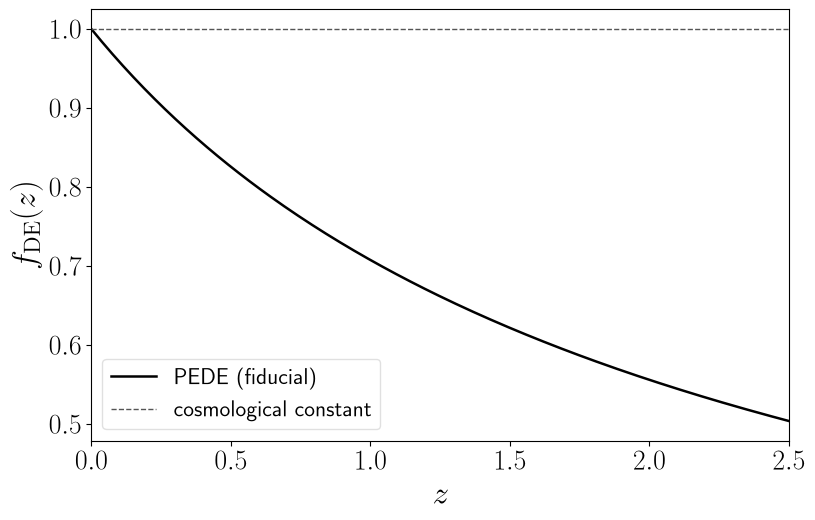

In [6]:
# Check: the script gives the formula of PEDE written above
z = np.linspace(0, 2.5, 200)
fde_formula = 1 - np.tanh(np.log10(1 + z))
print("largest difference from the formula:", np.max(np.abs(fde_true(z) - fde_formula)))

# Plot f_DE
fig, ax = plt.subplots(figsize=(9, 5.6))
ax.plot(z, fde_true(z), color="black", label="PEDE (fiducial)")
ax.axhline(1, color=GREY, lw=1, ls="--", label="cosmological constant")
ax.set_xlim(0, 2.5)
ax.set_xlabel(r"$z$")
ax.set_ylabel(r"$f_{\rm DE}(z)$")
ax.legend()
plt.show()

## 2. The catalog of mergers

The catalog has one row for each short GRB with a known redshift. The other columns describe the merger that we imagine behind it:

| column | meaning |
|---|---|
| `redshift`, `ra`, `dec`, `geocent_time` | redshift, position in the sky, arrival time |
| `chirp_mass` | $\mathcal M_c = (m_1m_2)^{3/5}/(m_1+m_2)^{1/5}$, the combination of the two masses that GW measure best, in solar masses. As seen at the detector: $(1+z)$ times larger than at the source |
| `mass_ratio` | $q=m_2/m_1$, at most 1 |
| `theta_jn` | $\theta_{\rm JN}$, angle between the line of sight and the axis of the binary. Close to 0° or 180°, because GRBs are seen along their jet |
| `psi`, `phase` | orientation of the binary in the sky, and its orbital phase at the merger |

`luminosity_distance` is 1 for all the events: it depends on the cosmology and is filled in below.

In [7]:
catalog = pd.read_hdf("code/input_data/injections_4gwfish_catalogs/" + settings["Catalog"])
print(len(catalog), "events")
catalog.head(4).round(3)

38 events


,chirp_mass,mass_ratio,luminosity_distance,dec,ra,theta_jn,psi,geocent_time,phase,redshift,event
0,1.945,0.935,1.0,0.506,3.300,3.087,0.992,799560032.0,0.014,0.225,GRB050509B
1,1.247,0.849,1.0,-0.681,0.402,3.075,1.423,804897410.0,2.176,0.161,GRB050709A
2,1.377,0.918,1.0,-0.481,4.297,0.038,0.839,806157262.0,4.260,0.254,GRB050724A
3,1.770,0.892,1.0,0.295,5.737,3.064,0.342,819078689.0,1.974,0.547,GRB051221A


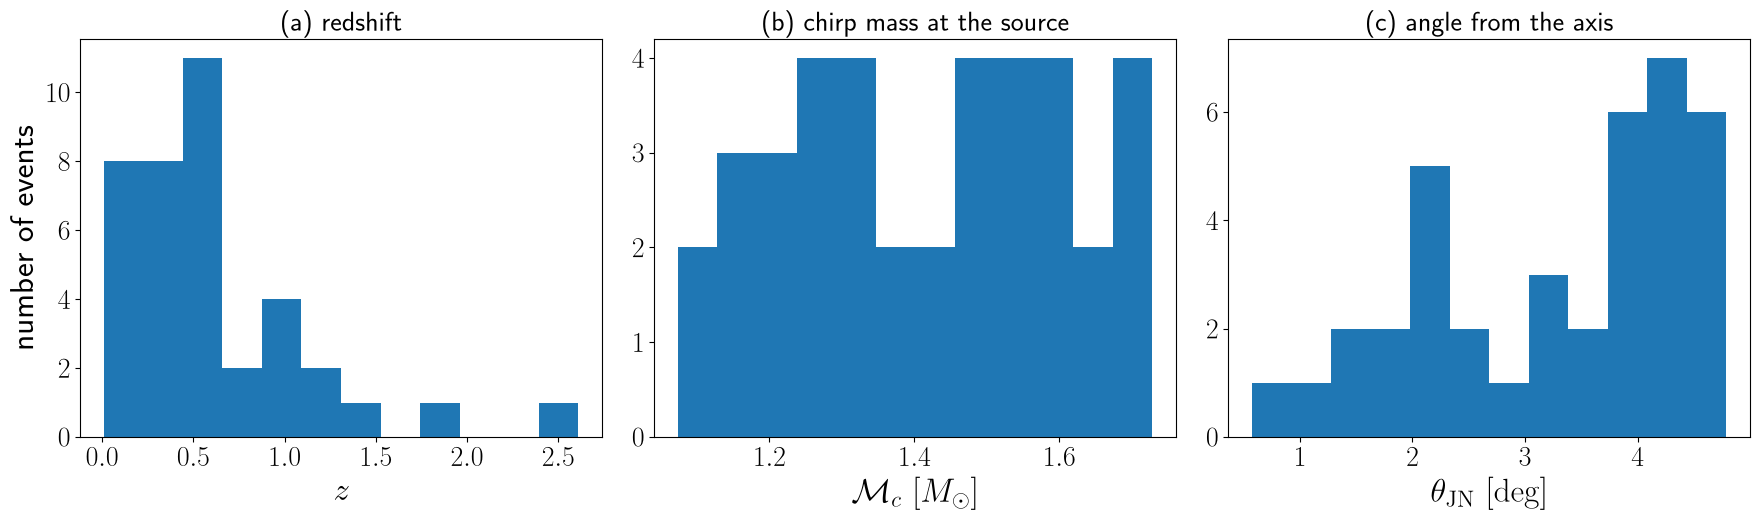

In [8]:
# theta_jn in degrees, measured from the closest end of the axis (180 degrees becomes 0)
theta_jn = np.degrees(catalog["theta_jn"])
theta_jn = np.minimum(theta_jn, 180 - theta_jn)

# Chirp mass at the source
chirp_mass_source = catalog["chirp_mass"] / (1 + catalog["redshift"])

fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))
axes[0].hist(catalog["redshift"], bins=12)
axes[0].set_xlabel(r"$z$")
axes[0].set_ylabel("number of events")
axes[0].set_title("(a) redshift")
axes[1].hist(chirp_mass_source, bins=12)
axes[1].set_xlabel(r"$\mathcal{M}_c\ [M_\odot]$")
axes[1].set_title("(b) chirp mass at the source")
axes[2].hist(theta_jn, bins=12)
axes[2].set_xlabel(r"$\theta_{\rm JN}\ [{\rm deg}]$")
axes[2].set_title("(c) angle from the axis")
fig.tight_layout()
plt.show()

`GenerateCatalog` gives each event the distance that its redshift has in the fiducial cosmology. The result is the list of **injections**: the true parameters of the simulated signals.

In [9]:
with capture_output():
    pipeline.GenerateCatalog(name, dL_true)

injections = pd.read_hdf(f"{pipeline.injectionGWfish}/injections_4gwfish_{name}.hdf5")
injections[["event", "redshift", "luminosity_distance"]].sort_values("redshift").head().round(3)

,event,redshift,luminosity_distance
29,GRB170817A,0.010,42.098
37,GRB230307A,0.065,292.272
36,GRB211211A,0.076,346.081
13,GRB080905A,0.122,572.366
4,GRB060614A,0.125,587.696


## 3. GWFish: what the Einstein Telescope measures

For each event GWFish computes

- the **SNR** (signal-to-noise ratio: how much the signal stands out from the noise of the detector). Events with SNR > 8 are detected;
- the **Fisher matrix**: its inverse, the *covariance matrix*, contains the errors on the parameters and their correlations.

**Duty cycle.** Each of the three interferometers of ET is on for 85% of the time. For each event GWFish draws at random which ones are on, so faint events may or may not be detected. `SEED` fixes which events are detected. (In GWFish, when only some of the three are off the SNR is lowered, but the Fisher matrix is still that of the full triangle.)

In [10]:
catalog_name = "fiducialchirpq"
gwfish_folder = Path(pipeline.output_GWFish) / name
gwfish_file = gwfish_folder / f"Errors_{catalog_name}_{name}.txt"

if REDO or not gwfish_file.exists():
    np.random.seed(SEED)
    with capture_output():
        pipeline.GWFishAnalysis(name)

# One row for each detected event: true parameters (as in the catalog) and errors (err_...)
detected = pd.read_csv(gwfish_file, sep=" ")
print(len(detected), "events detected, out of", len(injections))

34 events detected, out of 38


In [11]:
# Events that are not detected
is_lost = ~injections["event"].isin(detected["event"])
injections.loc[is_lost, ["event", "redshift"]]

,event,redshift
14,GRB090426A,2.609
16,GRB100117A,0.920
30,GRB181123B,1.754
35,GRB211023B,0.862


In [12]:
# The loudest events
columns = ["event", "redshift", "network_SNR", "luminosity_distance", "err_luminosity_distance"]
detected[columns].sort_values("network_SNR", ascending=False).head()

,event,redshift,network_SNR,luminosity_distance,err_luminosity_distance
27,GRB170817A,0.00979,1979.896491,42.1,0.1651
4,GRB060614A,0.12500,120.805131,587.7,14.9300
33,GRB230307A,0.06500,116.275010,292.3,9.2860
32,GRB211211A,0.07630,113.303710,346.1,7.2050
22,GRB150101B,0.13400,102.075846,634.0,21.2800


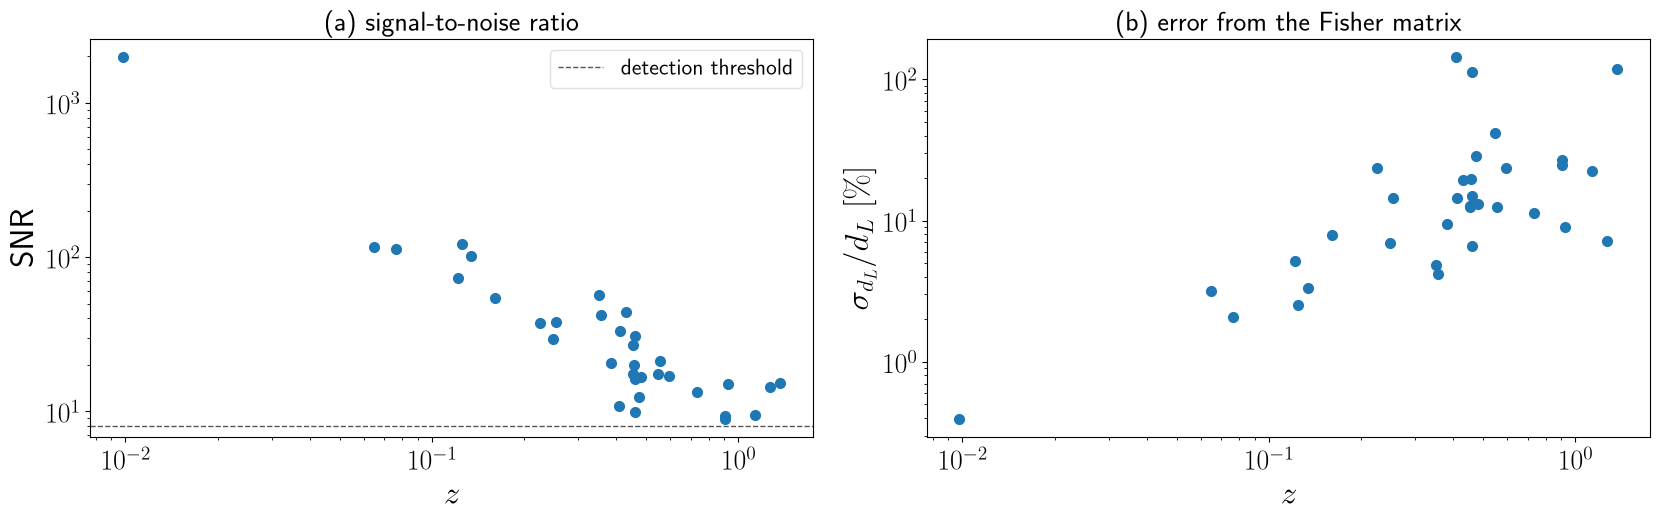

In [13]:
relative_error = detected["err_luminosity_distance"] / detected["luminosity_distance"]

fig, axes = plt.subplots(1, 2, figsize=(17, 5.6))
axes[0].loglog(detected["redshift"], detected["network_SNR"], "o")
axes[0].axhline(8, color=GREY, lw=1, ls="--", label="detection threshold")
axes[0].set_xlabel(r"$z$")
axes[0].set_ylabel("SNR")
axes[0].set_title("(a) signal-to-noise ratio")
axes[0].legend()
axes[1].loglog(detected["redshift"], 100 * relative_error, "o")
axes[1].set_xlabel(r"$z$")
axes[1].set_ylabel(r"$\sigma_{d_L}/d_L\ [\%]$")
axes[1].set_title("(b) error from the Fisher matrix")
fig.tight_layout()
plt.show()

Many errors on $d_L$ are very large. A distant binary seen face-on and a closer one that is tilted give almost the same signal, so GW alone confuse the distance and the angle $\theta_{\rm JN}$: this is called a **degeneracy**. The next step breaks it, using the fact that we saw a GRB.

## 4. Probability density of the distances

For each event `GWFishPosterior`

1. draws samples from the Gaussian described by the Fisher matrix, cut to the possible values of the parameters;
2. keeps them according to the **prior** (what we know before the measurement): the angle $\theta_{\rm JN}$ is within 5° of the axis, because we saw a GRB; each star weighs between 1.1 and 2.5 solar masses; mergers are spread uniformly in the volume of the Universe. The result is the **posterior**: the probability of the parameters given the data and the prior;
3. turns the samples of $d_L$ into a smooth curve with a **KDE** (kernel density estimate: a smoothed histogram);
4. below redshift 0.15 it widens the curve, to include the **peculiar velocities** (motions of the galaxies on top of the expansion, which change the redshift).

The mock measurement is *noiseless*: the densities are centred on the true distance, not scattered around it.

The result is a `.pkl` file, which is the input of the next sections. The one computed here is also distributed with the repo, in `cobaya_data`. If you compute it again you get the same events, and densities that differ by about 0.02 times their width at most, because part of the random numbers does not follow `SEED`.

In [14]:
file_name = f"ET_delta_{name}_{catalog_name}"
data_folder = Path(pipeline.MCMCdir) / name / file_name
data_file = data_folder / (file_name + ".pkl")

if REDO or not data_file.exists():
    np.random.seed(SEED)
    with capture_output():
        pipeline.GWFishPosterior(name, dL_true, settings["NSampling"],
                                 cosmo_model=cosmo, include_vp=True)

with open(data_file, "rb") as f:
    events, z_gw, density_gw, dL_gw, sigma_fisher, density_vp = dill.load(f)

# events       : names
# z_gw         : redshifts
# density_gw   : probability density of d_L from GW
# dL_gw        : true d_L
# sigma_fisher : error on d_L from the Fisher matrix
# density_vp   : probability density of d_L, with peculiar velocities. Used in the analysis
z_gw = np.array(z_gw)
dL_gw = np.array(dL_gw)
sigma_fisher = np.array(sigma_fisher)
print(len(events), "events in", data_file)

34 events in code/output_mcmc/PEDE/ET_delta_PEDE_fiducialchirpq/ET_delta_PEDE_fiducialchirpq.pkl


In [15]:
# Mean and standard deviation of each density
mean_vp, sigma_vp = np.array([gp_tools.mean_and_std(d) for d in density_vp]).T
mean_post, sigma_post = np.array([gp_tools.mean_and_std(d) for d in density_gw]).T

table = pd.DataFrame({
    "event": events,
    "z": z_gw,
    "true dL": dL_gw,
    "error: Fisher": sigma_fisher,
    "error: posterior": sigma_post,
    "error: + pec. velocity": sigma_vp,
    "(mean - true) / error": (mean_vp - dL_gw) / sigma_vp,
})
table = table.sort_values("z")
table.head(10).round(3)

,event,z,true dL,error: Fisher,error: posterior,error: + pec. velocity,(mean - true) / error
27,GRB170817A,0.010,42.1,0.165,0.061,2.742,0.013
33,GRB230307A,0.065,292.3,9.286,1.964,3.172,0.038
32,GRB211211A,0.076,346.1,7.205,2.473,3.852,0.153
13,GRB080905A,0.122,572.4,29.370,6.150,7.043,0.183
4,GRB060614A,0.125,587.7,14.930,4.070,5.370,0.149
22,GRB150101B,0.134,634.0,21.280,6.294,6.934,0.155
1,GRB050709A,0.161,776.1,61.090,11.998,11.998,0.054
0,GRB050509B,0.225,1130.0,266.700,30.399,30.399,0.022
28,GRB191019A,0.248,1263.0,88.140,42.858,42.858,0.025
2,GRB050724A,0.254,1299.0,187.300,34.309,34.309,-0.008


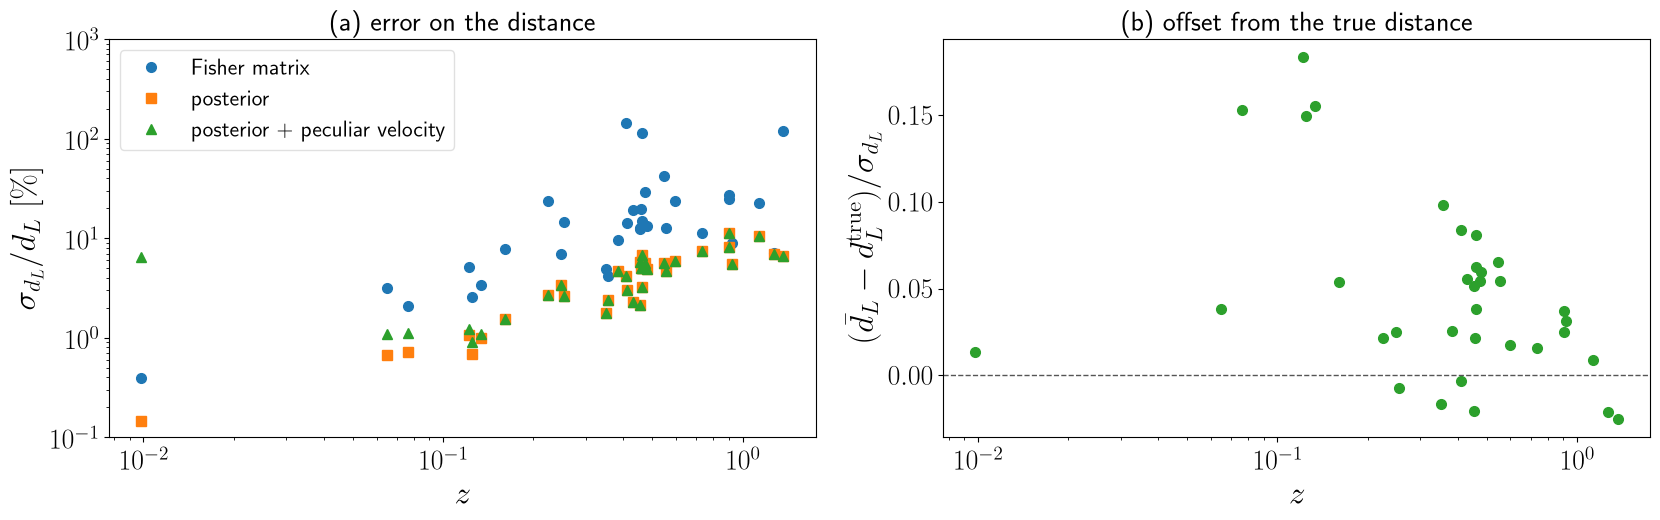

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.6))

# Errors at the three stages
axes[0].loglog(z_gw, 100 * sigma_fisher / dL_gw, "o", label="Fisher matrix")
axes[0].loglog(z_gw, 100 * sigma_post / dL_gw, "s", label="posterior")
axes[0].loglog(z_gw, 100 * sigma_vp / dL_gw, "^", label="posterior + peculiar velocity")
axes[0].set_ylim(0.1, 1e3)
axes[0].set_xlabel(r"$z$")
axes[0].set_ylabel(r"$\sigma_{d_L}/d_L\ [\%]$")
axes[0].set_title("(a) error on the distance")
axes[0].legend(loc="upper left")

# Are the densities centred on the true distance?
axes[1].semilogx(z_gw, (mean_vp - dL_gw) / sigma_vp, "o", color="C2")
axes[1].axhline(0, color=GREY, lw=1, ls="--")
axes[1].set_xlabel(r"$z$")
axes[1].set_ylabel(r"$(\bar{d}_L - d_L^{\rm true})/\sigma_{d_L}$")
axes[1].set_title("(b) offset from the true distance")
fig.tight_layout()
plt.show()

The GRB reduces the error on the distance a lot (circles to squares). Peculiar velocities matter only for the closest events.

The density of some events, compared with the Gaussian of the Fisher matrix. Each curve is divided by its maximum.

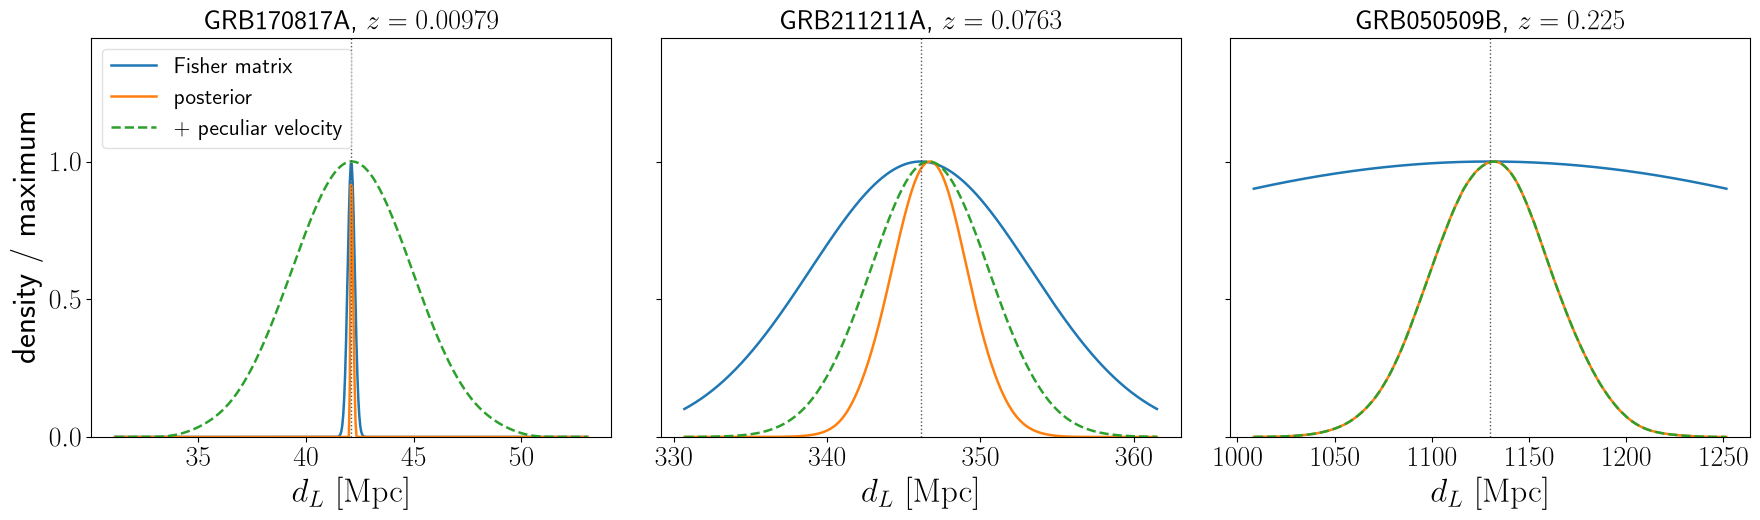

In [17]:
examples = ["GRB170817A", "GRB211211A", "GRB050509B"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.6), sharey=True)
for ax, event in zip(axes, examples):
    i = events.index(event)
    x = np.linspace(dL_gw[i] - 4 * sigma_vp[i], dL_gw[i] + 4 * sigma_vp[i], 500)
    gaussian = np.exp(-(x - dL_gw[i])**2 / (2 * sigma_fisher[i]**2))

    ax.plot(x, gaussian, label="Fisher matrix")
    ax.plot(x, density_gw[i](x), label="posterior")
    ax.plot(x, density_vp[i](x), ls="--", label="+ peculiar velocity")
    ax.axvline(dL_gw[i], color=GREY, lw=1, ls=":")
    ax.set_ylim(0, 1.45)
    ax.set_yticks([0, 0.5, 1])
    ax.set_xlabel(r"$d_L\ [{\rm Mpc}]$")
    ax.set_title(f"{event}, $z={z_gw[i]:.3g}$")
axes[0].set_ylabel("density / maximum")
axes[0].legend(loc="upper left")
fig.tight_layout()
plt.show()

## 5. Supernovae

Type Ia supernovae (SNe) all have nearly the same *absolute magnitude* $M_b$ (intrinsic brightness, on a logarithmic scale). How bright they appear, $m_b$, gives their distance:

$$m_b = 5\log_{10}\left(\frac{d_L}{\rm Mpc}\right) + 25 + M_b .$$

$M_b$ is not known, so SNe alone give only relative distances. GW give absolute distances, so the two together also measure $M_b$.

**Pantheon+** is a sample of about 1600 SNe at $z>0.01$. We take their redshifts and errors (with correlations), and simulate their magnitudes in the fiducial cosmology. This is important: combining SNe from one cosmology and GW from another would give a wrong result.

To use the real data instead, set `sn_dataset = "PantheonPlus/config.dataset"` in the next cell.

In [18]:
from sn_mock import make_sn_mock

gp_tools.download_pantheonplus()                         # only the first time
sn_dataset, Mb_true = make_sn_mock(cosmo, name, seed=SEED)
sn, sn_covariance = gp_tools.read_sn(name)

print(len(sn), "supernovae, true M_b =", round(Mb_true, 3))

1590 supernovae, true M_b = -19.378


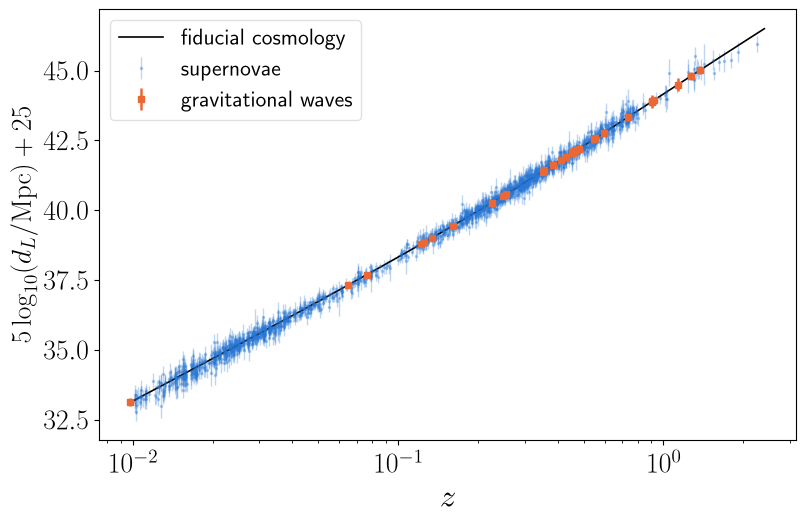

In [19]:
def distance_modulus(dL):
    """Logarithmic distance used for supernovae."""
    return 5 * np.log10(dL) + 25

# Distance modulus of the two data sets
mu_sn = sn["m_b_corr"] - Mb_true
mu_gw = distance_modulus(mean_vp)
error_mu_gw = 5 / np.log(10) * sigma_vp / mean_vp

# Hubble diagram: distance as a function of redshift
z = np.logspace(-2, np.log10(2.4), 200)
fig, ax = plt.subplots(figsize=(9, 5.6))
ax.errorbar(sn["zHD"], mu_sn, sn["m_b_corr_err_DIAG"], fmt=".", ms=3, lw=1, color=COLOR["PantheonPlus-ET-delta"],
            alpha=0.3, label="supernovae")
ax.errorbar(z_gw, mu_gw, error_mu_gw, fmt="s", ms=5, color=COLOR["ET-delta"], label="gravitational waves")
ax.plot(z, distance_modulus(dL_true(z)), color="black", lw=1.2, label="fiducial cosmology")
ax.set_xscale("log")
ax.set_xlabel(r"$z$")
ax.set_ylabel(r"$5\log_{10}(d_L/{\rm Mpc}) + 25$", fontsize=20)
ax.legend()
plt.show()

## 6. The Gaussian process

A **Gaussian process** (GP) draws whole curves at random. We use it for $f_{\rm DE}(z)$, instead of choosing a formula. The curves depend on

- $\sigma_f$: how far they go from $f_{\rm DE}=1$ (the cosmological constant);
- $\ell_f$: over which redshift interval they change;
- `random`, which selects one curve among all the possible ones. It fixes the *seed* of the random numbers, `seed = int(1e5 * random)`.

The same $(\sigma_f, \ell_f, {\rm seed})$ always gives the same curve. All the curves have $f_{\rm DE}(0)=1$, which is the definition of $f_{\rm DE}$.

The file `theory/DDE.py` draws the curve, computes $H(z)$, and gives the **same** distances to the GW and to the SNe.

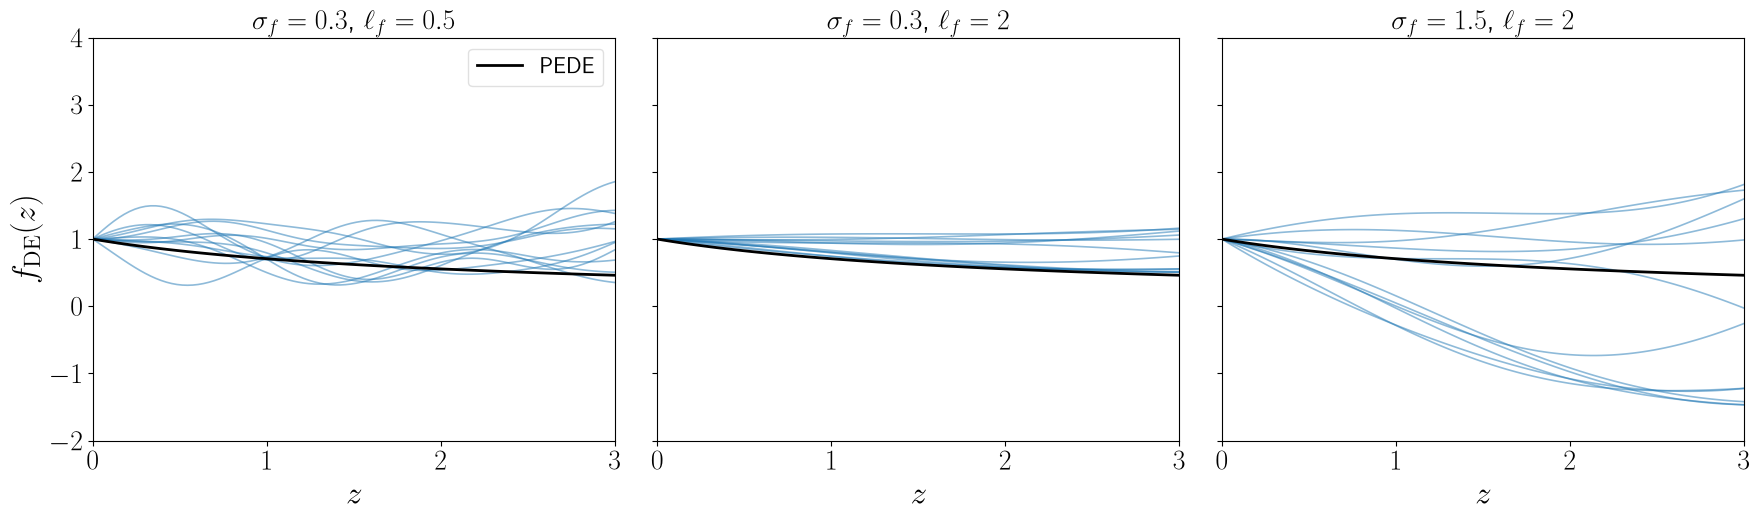

In [20]:
# Some curves drawn by the GP
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6), sharey=True)
for ax, (sigma_f, ell_f) in zip(axes, [(0.3, 0.5), (0.3, 2), (1.5, 2)]):
    for seed in range(12):
        curve = gp_tools.fde_gp(gp_tools.Z_GRID, sigma_f, ell_f, seed)
        ax.plot(gp_tools.Z_GRID, curve, color="C0", lw=1.2, alpha=0.5)
    ax.plot(gp_tools.Z_GRID, fde_true(gp_tools.Z_GRID), color="black", lw=2, label="PEDE")
    ax.set_title(rf"$\sigma_f = {sigma_f}$, $\ell_f = {ell_f}$")
    ax.set_xlabel(r"$z$")
    ax.set_xlim(0, 3)
    ax.set_xticks([0, 1, 2, 3])
    ax.set_ylim(-2, 4)
axes[0].set_ylabel(r"$f_{\rm DE}(z)$")
axes[0].legend()
fig.tight_layout()
plt.show()

## 7. The likelihood and the MCMC

### The structure of the likelihood

The **likelihood** is the probability of the data for given values of the parameters. For each set of parameters, `theory/DDE.py` gives the distances $d_L^{\rm th}(z)$, and the likelihoods compare them with the data:

$$\ln\mathcal L=\ln\mathcal L_{\rm GW}+\ln\mathcal L_{\rm SN}\,.$$

**Gravitational waves** (`likelihood/MMcosmologyGP.py`). The redshifts are known, so only the distances are compared. There are two ways, selected with `interpolation_method` in the Cobaya yaml file.

*`interpolation_method: kde`* (used in this notebook). Each event contributes with its probability density of the distance $p_i(d_L)$ (the KDE of section 4), evaluated at the distance predicted for its redshift:

$$\ln\mathcal L_{\rm GW}=\sum_{i=1}^{N}\ln p_i\!\left(d_L^{\rm th}(z_i)\right).$$

- No Gaussian approximation is made: $p_i$ can have any shape.
- Each $p_i$ is divided by its maximum. This only adds a constant to $\ln\mathcal L$, which does not change the results.
- $p_i=0$ outside the range of its samples: if one event cannot be explained, the parameters are rejected.

*`interpolation_method: gaussian`*. The usual $\chi^2$, with the distances $d_{L,i}$ of the events and the errors $\sigma_i$ of the Fisher matrix of GWFish:

$$\ln\mathcal L_{\rm GW}=-\frac12\,\chi^2\,,\qquad \chi^2=\sum_{i=1}^{N}\left[\frac{d_L^{\rm th}(z_i)-d_{L,i}}{\sigma_i}\right]^2.$$

- It is simpler and needs no densities, but it uses less information: $\sigma_i$ does not include the prior on $\theta_{\rm JN}$ given by the GRB, so most errors are much larger than those of the KDE (section 4).
- $\sigma_i$ does not include the peculiar velocities either. This option therefore needs `peculiar_velocity: None`; with `integrated` it stops with an error.

**Supernovae** (`sn.pantheonplus`, part of Cobaya). Gaussian in the magnitudes, with the covariance matrix $C$ and the free parameter $M_b$:

$$\ln\mathcal L_{\rm SN}=-\tfrac12\sum_{jl} r_j\,(C^{-1})_{jl}\,r_l\,,\qquad r_j=m_{b,j}-5\log_{10}\frac{d_L^{\rm th}(z_j)}{\rm Mpc}-25-M_b\,.$$

The line `provides: ['angular_diameter_distance']` in the settings makes the SNe use the distances computed with the GP.

### What you have to provide

The GW likelihood reads one file, `<gw_network>_<fiducial_cosmology>_<grb_dataset>.pkl`, in the folder `data_directory`. These names are set in the files `input_cobaya/*.yaml`:

| option | here | meaning |
|---|---|---|
| `data_directory` | `cobaya_data` (this notebook uses the file of section 4) | folder of the file |
| `gw_network` | `ET_delta` | first part of the file name |
| `fiducial_cosmology` | `PEDE` | second part of the file name |
| `grb_dataset` | `fiducialchirpq` | third part of the file name |
| `interpolation_method` | `kde` | `kde` or `gaussian`, see above |
| `peculiar_velocity` | `integrated` | which densities to use with `kde`, see below. `None` with `gaussian` |

The file contains a list:

| position | content | used by the likelihood |
|---|---|---|
| 0 | names of the events | no |
| 1 | redshifts | **always** |
| 2 | densities $p_i(d_L)$ from GW only: one function (KDE) for each event | `kde` with `peculiar_velocity: None` |
| 3 | true distances | `gaussian` |
| 4 | errors from the Fisher matrix | `gaussian` |
| 5 | densities with peculiar velocities | `kde` with `peculiar_velocity: integrated` |

(With `SavePosteriorBool: True` in the settings of `mm_gw.py` the samples of $d_L$ are also saved, in position 2, and the rest moves by one. The likelihood recognises it.)

### With or without peculiar velocities

Only for `interpolation_method: kde`:

- `peculiar_velocity: integrated` uses the densities in position 5. Only the events at $z\le0.15$ are different from those in position 2. Use it for real analyses.
- `peculiar_velocity: None` uses the densities from GW only. Position 5 is then not needed, so you can give a file without it. If it is missing and you ask for `integrated`, the likelihood stops with an error.

It makes a difference: without peculiar velocities the closest event, GRB170817A, has an error on $d_L$ of 0.15% instead of 6.5%, and alone it would almost fix $H_0$.

### Your own densities

If you have samples of $d_L$ for your events, for example from a parameter-estimation code, you can make the file yourself:

```python
import dill
from getdist import MCSamples

densities = []
for samples in my_samples:                               # one array of d_L [Mpc] for each event
    kde = MCSamples(samples=samples, names=["dL"])
    densities.append(kde.get1DDensityGridData("dL"))     # a function: density(dL)

data = [names, redshifts, densities, distances, errors]  # add the densities with vp, if you have them
with open("my_folder/ET_delta_MyCosmology_mycatalog.pkl", "wb") as f:
    dill.dump(data, f)
```

Then set `data_directory: my_folder`, `fiducial_cosmology: MyCosmology`, `grb_dataset: mycatalog` (and `peculiar_velocity: None`, if you did not add them). The samples should follow the likelihood of $d_L$, or a posterior whose prior on $d_L$ is not too important.

For `interpolation_method: gaussian` the densities are not needed: `data = [names, redshifts, None, distances, errors]`.

### Test the likelihood

Before sampling, check that both likelihoods change when the GP curve changes. `sigma_f = 0.0001` is practically a cosmological constant.

In [21]:
# Settings of the two runs
info = {}
for run in RUNS:
    info[run] = gp_tools.cobaya_settings(run, data_folder, sn_dataset, RMINUS1_STOP, SEED)

# Log-likelihoods for three curves
with capture_output():
    model = gp_tools.cobaya_model(info["PantheonPlus-ET-delta"])

h = H0 / 100
point = {"h": h, "Omega_cdm": Omega_m - 0.0224 / h**2, "ell_f": 2, "random": 3.0, "Mb": Mb_true}
for sigma_f in [0.0001, 0.5, 1.0]:
    point["sigma_f"] = sigma_f
    loglike_gw, loglike_sn = model.logposterior(point).loglikes
    print(f"sigma_f = {sigma_f:6.4f}   log-likelihood:  GW {loglike_gw:7.2f}   SNe {loglike_sn:8.2f}")

sigma_f = 0.0001   log-likelihood:  GW   -6.84   SNe  -814.15
sigma_f = 0.5000   log-likelihood:  GW   -2.88   SNe  -797.07
sigma_f = 1.0000   log-likelihood:  GW   -0.59   SNe  -788.11


In [22]:
# GW likelihood with and without peculiar velocities, for different values of h.
# The curve is practically a cosmological constant
from copy import deepcopy

loglike = {}
h_values = [0.69, 0.70, 0.71, 0.72]
for option in ["integrated", "None"]:
    test_info = deepcopy(info["ET-delta"])
    test_info["likelihood"]["likelihood.MMcosmologyGP"]["peculiar_velocity"] = option
    with capture_output():
        model = gp_tools.cobaya_model(test_info)

    loglike[option] = []
    for h in h_values:
        point = {"h": h, "Omega_cdm": 0.25, "sigma_f": 0.0001, "ell_f": 2, "random": 3.0}
        loglike[option].append(model.logposterior(point).loglikes[0])

pd.DataFrame(loglike, index=pd.Index(h_values, name="h")).round(1)

,integrated,None
h,,
0.69,-2.7,-inf
0.70,-3.9,-5.7
0.71,-18.3,-inf
0.72,-44.7,-inf


Without peculiar velocities (column `None`) the likelihood falls much faster when $h$ moves away from its best value; `-inf` means that at least one event cannot be explained.

### The MCMC

The free parameters are $h = H_0/100$, $\Omega_c$ (fraction of cold dark matter), the three GP parameters and, with the SNe, $M_b$. The fraction of ordinary matter is fixed ($\Omega_b h^2 = 0.0224$). Their allowed ranges are in `input_cobaya/ET-delta.yaml` and `input_cobaya/PantheonPlus-ET-delta.yaml`, the settings read by **Cobaya**, the code that does the sampling.

The sampler is an **MCMC** (Markov chain Monte Carlo): chains that walk in the space of the parameters and visit each region in proportion to its probability. Four chains run in parallel. **$R-1$** measures how different they are: sampling stops when it is below `RMINUS1_STOP`.

Only ~7% of the steps are accepted, because a small change of `random` gives a completely different curve.

From the terminal:
```
OMP_NUM_THREADS=1 mpirun -n 4 cobaya-run input_cobaya/PantheonPlus-ET-delta.yaml
```

In [23]:
for run in RUNS:
    gp_tools.run_mcmc(info[run], n_chains=N_CHAINS, redo=REDO)

ET-delta: already converged, using the existing chains
PantheonPlus-ET-delta: already converged, using the existing chains


In [24]:
# Read the chains, without the first 30% (burn-in: the walk to the region of high probability)
chains = {}
for run in RUNS:
    chains[run] = gp_tools.load_chains(run)

### Can we trust the chains?

$R-1$ can be small by chance, so we also compare the four chains directly. The **effective sample size** (ESS) is the number of independent samples in a chain.

In [25]:
for run in RUNS:
    print(NAME[run])
    print(gp_tools.compare_chains(chains[run]).to_string(index=False), "\n")

ET Δ
 chain  mean h  mean Omega_m  ESS Omega_m
     1  0.6995         0.257        476.0
     2  0.6998         0.256        327.0
     3  0.6994         0.260        416.0
     4  0.6994         0.254        499.0 

ET Δ + Pantheon+
 chain  mean h  mean Omega_m  ESS Omega_m
     1  0.7022         0.327        119.0
     2  0.7021         0.327        132.0
     3  0.7018         0.321        239.0
     4  0.7020         0.330        135.0 



The means of the chains agree. The ESS of $\Omega_m$ is small, so medians and 68% intervals are reliable, while the 95% limits are noisier. For precise 95% limits, use a smaller `RMINUS1_STOP`.

## 8. Results

### Parameters
Median and 68% interval, compared with the true values.

In [26]:
true_values = {"h": H0 / 100, "Omega_m": Omega_m, "Mb": Mb_true}

rows = []
for run in RUNS:
    for parameter in ["h", "Omega_m", "Mb"]:
        if parameter == "Mb" and run == "ET-delta":
            continue                                # no supernovae in this run
        samples = chains[run][parameter]
        low, median, high = [chains[run].confidence(samples, level) for level in (0.16, 0.5, 0.84)]
        rows.append({"data": NAME[run], "parameter": parameter, "median": median,
                     "error -": median - low, "error +": high - median, "true": true_values[parameter]})

pd.DataFrame(rows).round(4)

,data,parameter,median,error -,error +,true
0,ET Δ,h,0.6995,0.0048,0.0049,0.7030
1,ET Δ,Omega_m,0.2530,0.0580,0.0661,0.2950
2,ET Δ + Pantheon+,h,0.7019,0.0034,0.0037,0.7030
3,ET Δ + Pantheon+,Omega_m,0.3190,0.0612,0.0728,0.2950
4,ET Δ + Pantheon+,Mb,-19.3821,0.0091,0.0097,-19.3784


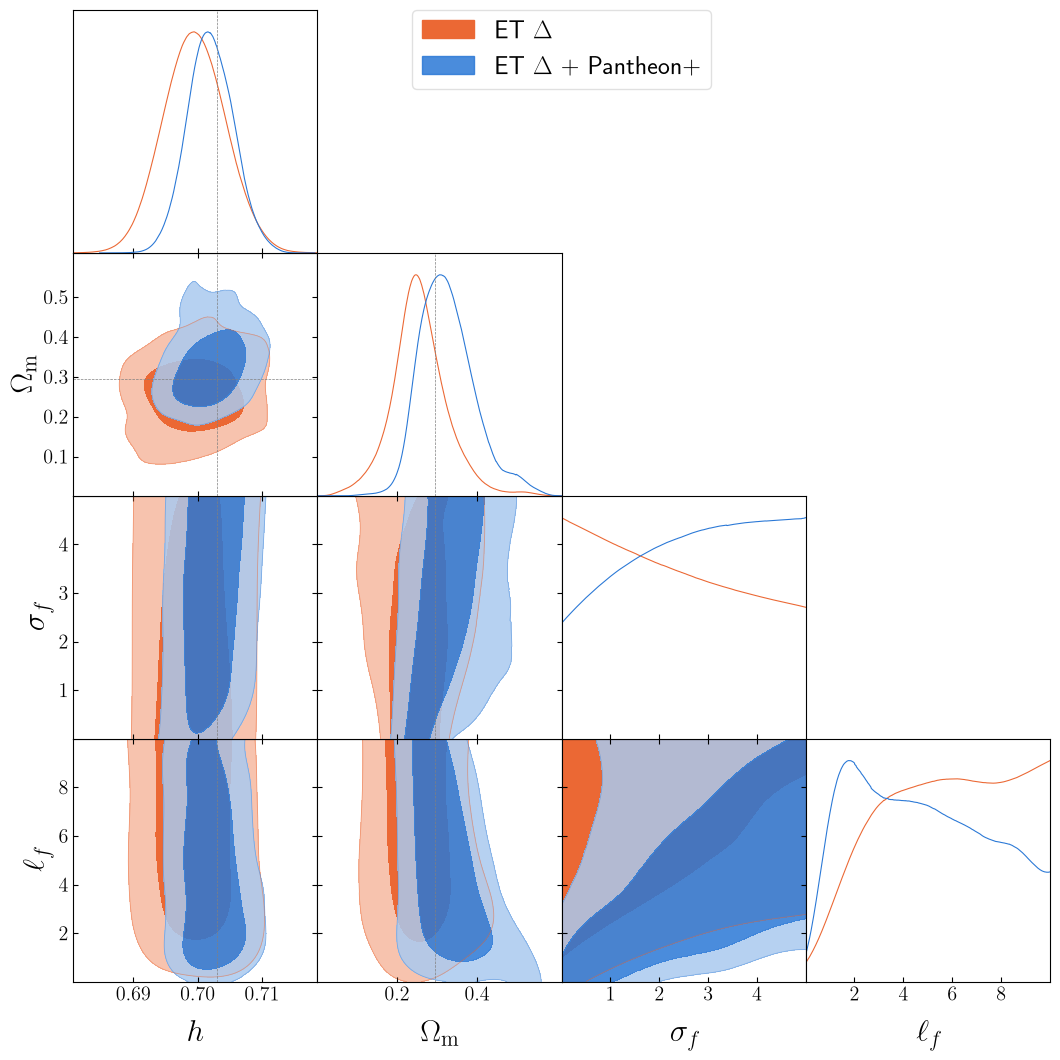

In [27]:
from getdist import plots

plotter = plots.get_subplot_plotter(width_inch=11)
plotter.settings.axes_fontsize = 16
plotter.settings.axes_labelsize = 24
plotter.settings.legend_fontsize = 20
plotter.triangle_plot([chains[run] for run in RUNS],
                      ["h", "Omega_m", "sigma_f", "ell_f"],
                      filled=True,
                      contour_colors=[COLOR[run] for run in RUNS],
                      legend_labels=[LABEL[run] for run in RUNS],
                      markers={"h": H0 / 100, "Omega_m": Omega_m})      # dashed: true values
plt.show()

$\Omega_m$ is poorly measured. Distances depend only on the sum $\Omega_m(1+z)^3+(1-\Omega_m)f_{\rm DE}(z)$: more matter can be compensated by less dark energy (the **dark degeneracy**). The expansion rate $H(z)$ is what the data really measure.

### Curves
Each sample of the chains corresponds to a curve $f_{\rm DE}(z)$ and to one $H(z)$. `redraw_curves` computes them again, and checks that they are the ones used in the sampling.

In [28]:
fde_curves = {}
H_curves = {}
for run in RUNS:
    print(NAME[run], end=": ")
    with capture_output() as output:
        fde_curves[run], H_curves[run] = gp_tools.redraw_curves(chains[run], info[run], seed=SEED)
    print(output.stdout.splitlines()[-1])

ET Δ: 

3996 curves redrawn, 4 dropped (0.10%)
ET Δ + Pantheon+: 

3977 curves redrawn, 23 dropped (0.57%)


### $H(z)$ directly from the distances

The GP is one way to get $H(z)$. As a comparison, we also get it without any model of dark energy, from the *slope* of the distance as a function of redshift. The procedure is explained in the **appendix** at the end of the notebook.

In [29]:
# Redshifts where H is free (see the appendix)
knots_gw = [0.01, 0.2, 0.5, 0.9, 1.4]
knots_sn = [0.01, 0.2, 0.5, 0.9, 2.3]

H_points = {}           # H at the knots
H_errors = {}           # errors
H_correlation = {}      # correlations between the errors

run = "ET-delta"
H_points[run], H_errors[run], H_correlation[run] = gp_tools.fit_H(knots_gw, z_gw, mean_vp, sigma_vp)

run = "PantheonPlus-ET-delta"
H_points[run], H_errors[run], H_correlation[run] = gp_tools.fit_H(knots_sn, z_gw, mean_vp, sigma_vp,
                                                                  sn, sn_covariance)

# Redshifts of the points that we show: all the knots but the last one
z_points = np.array(knots_gw[:-1])

for run in RUNS:
    H = H_points[run][:-1]
    error = H_errors[run][:-1]
    print(NAME[run])
    print(pd.DataFrame({"z": z_points, "H": H, "error": error, "error [%]": 100 * error / H,
                        "true H": H_true(z_points)}).round(2).to_string(index=False), "\n")

ET Δ
   z      H  error  error [%]  true H
0.01  70.40   1.01       1.44   70.51
0.20  75.60   1.05       1.39   75.69
0.50  88.14   4.09       4.64   88.31
0.90 111.74  18.25      16.33  111.99 

ET Δ + Pantheon+
   z      H  error  error [%]  true H
0.01  70.33   0.37       0.53   70.51
0.20  75.65   0.43       0.56   75.69
0.50  86.96   1.31       1.50   88.31
0.90 112.18   4.22       3.76  111.99 



### Reconstruction of $f_{\rm DE}(z)$ and $H(z)$

The bands contain 68% and 95% of the curves. $H(z)$ is divided by the one of $\Lambda$CDM (a cosmological constant plus cold dark matter) with the default parameters of CLASS. Its $H_0$ is different from ours, so the ratio is not 1 at $z=0$.

In [30]:
z = np.logspace(-2, np.log10(2.5), 100)

# Expansion rate of LCDM, default parameters of CLASS
lcdm = Class()
lcdm.compute()

def H_lcdm(z):
    return np.array([lcdm.Hubble(zi) for zi in z]) * gp_tools.C_KM_S

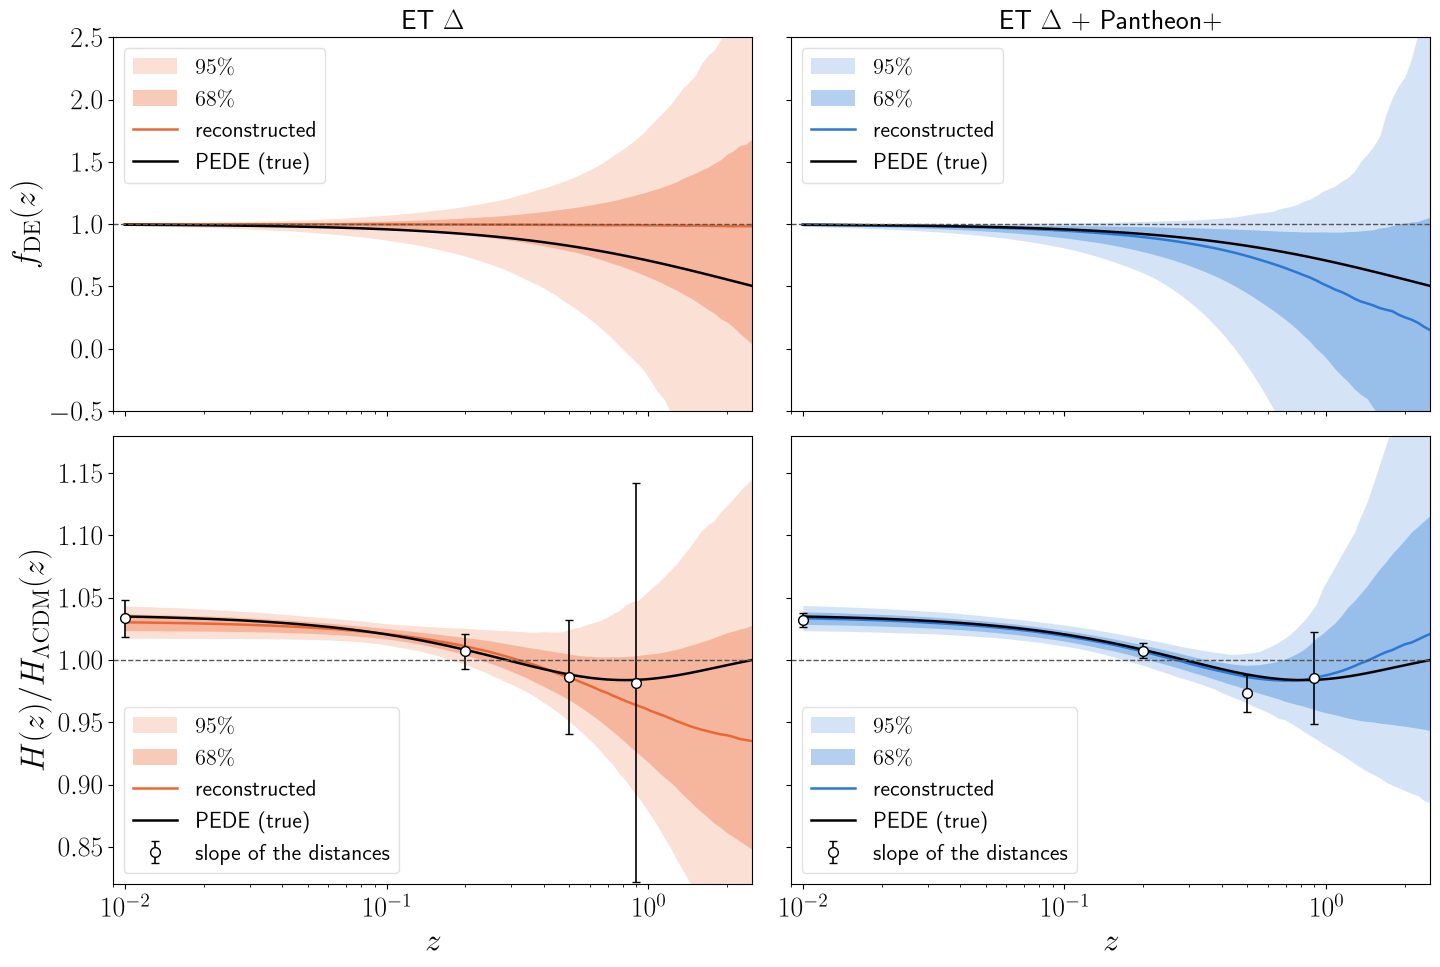

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(17, 11), sharex=True, sharey="row",
                         gridspec_kw={"hspace": 0.06, "wspace": 0.06, "height_ratios": [1, 1.2]})

for column, run in enumerate(RUNS):
    color = COLOR[run]
    ax_fde = axes[0, column]
    ax_H = axes[1, column]

    # Top: f_DE
    low95, low68, median, high68, high95 = gp_tools.bands(fde_curves[run], z)
    ax_fde.fill_between(z, low95, high95, color=color, alpha=0.2, lw=0, label=r"$95\%$")
    ax_fde.fill_between(z, low68, high68, color=color, alpha=0.35, lw=0, label=r"$68\%$")
    ax_fde.plot(z, median, color=color, label="reconstructed")
    ax_fde.plot(z, fde_true(z), color="black", label="PEDE (true)")
    ax_fde.axhline(1, color=GREY, lw=1, ls="--")
    ax_fde.set_title(LABEL[run])
    ax_fde.legend(loc="upper left")

    # Bottom: H / H_LCDM
    low95, low68, median, high68, high95 = gp_tools.bands(H_curves[run], z) / H_lcdm(z)
    ax_H.fill_between(z, low95, high95, color=color, alpha=0.2, lw=0, label=r"$95\%$")
    ax_H.fill_between(z, low68, high68, color=color, alpha=0.35, lw=0, label=r"$68\%$")
    ax_H.plot(z, median, color=color, label="reconstructed")
    ax_H.plot(z, H_true(z) / H_lcdm(z), color="black", label="PEDE (true)")
    ax_H.errorbar(z_points, H_points[run][:-1] / H_lcdm(z_points), H_errors[run][:-1] / H_lcdm(z_points),
                  fmt="o", color="black", mfc="white", capsize=3, lw=1.2, label="slope of the distances")
    ax_H.axhline(1, color=GREY, lw=1, ls="--")
    ax_H.set_xlabel(r"$z$")
    ax_H.legend(loc="lower left")

axes[0, 0].set_xscale("log")
axes[0, 0].set_xlim(0.009, 2.5)
axes[0, 0].set_ylim(-0.5, 2.5)
axes[0, 0].set_ylabel(r"$f_{\rm DE}(z)$")
axes[1, 0].set_ylim(0.82, 1.18)
axes[1, 0].set_ylabel(r"$H(z)/H_{\Lambda{\rm CDM}}(z)$")
plt.show()

In [32]:
# Is the true cosmology inside the 95% bands?
z_check = np.array([0.1, 0.3, 0.5, 1.0, 1.5])
for run in RUNS:
    fde_band = gp_tools.bands(fde_curves[run], z_check)
    H_band = gp_tools.bands(H_curves[run], z_check)
    print(NAME[run])
    for i in range(len(z_check)):
        fde_ok = fde_band[0, i] < fde_true(z_check)[i] < fde_band[4, i]
        H_ok = H_band[0, i] < H_true(z_check)[i] < H_band[4, i]
        print(f"   z = {z_check[i]}:  f_DE inside: {fde_ok}   H inside: {H_ok}")

ET Δ
   z = 0.1:  f_DE inside: True   H inside: True
   z = 0.3:  f_DE inside: True   H inside: True
   z = 0.5:  f_DE inside: True   H inside: True
   z = 1.0:  f_DE inside: True   H inside: True
   z = 1.5:  f_DE inside: True   H inside: True
ET Δ + Pantheon+
   z = 0.1:  f_DE inside: True   H inside: True
   z = 0.3:  f_DE inside: True   H inside: True
   z = 0.5:  f_DE inside: True   H inside: True
   z = 1.0:  f_DE inside: True   H inside: True
   z = 1.5:  f_DE inside: True   H inside: True


## Things to remember

- **Look at $H(z)$ first.** $f_{\rm DE}(z)$ and $\Omega_m$ can compensate each other, so a wide or shifted band of $f_{\rm DE}$ does not mean that the data disagree with the true cosmology.
- **The mock data**: the GW densities are noiseless, while the SNe have one random realisation of the noise.
- **The prior on the distances** (section 4) is computed in the fiducial cosmology. Its effect on $H_0$ is much smaller than the error.
- **The ranges allowed for $\sigma_f$ and $\ell_f$** influence the result where there are few data ($z\gtrsim1.5$).
- **The 95% limits** are noisier than the 68% ones (section 7).

## Appendix: how the $H(z)$ points are obtained

**Idea.** In a flat universe

$$\frac{d_L(z)}{1+z}=\int_0^z \frac{c}{H(z')}\,dz' \qquad\Longrightarrow\qquad \frac{c}{H(z)}=\frac{d}{dz}\left[\frac{d_L(z)}{1+z}\right].$$

The expansion rate is the inverse of a *slope*. One event gives only one value of $d_L$, i.e. the integral of $c/H$ from 0 to its redshift, and cannot tell what $H$ is at that redshift. We need all the events together.

**Procedure** (function `fit_H` in `code/gp_tools.py`)

1. Choose a few redshifts $z_k$, the **knots**: 0.01, 0.2, 0.5, 0.9, and one at the end of the data.
2. The free parameters are the values of $c/H$ at the knots. With supernovae, also their absolute magnitude $M_b$.
3. A smooth curve (a cubic spline) through these values gives $c/H$ at all redshifts.
4. The integral of the curve from 0 to $z$, multiplied by $1+z$, is the predicted distance $d_L^{\rm th}(z)$.
5. The best values minimise

   $$\chi^2=\sum_{i}^{\rm GW}\left[\frac{d_L^{\rm th}(z_i)-\bar d_{L,i}}{\sigma_i}\right]^2+\sum_{jl}^{\rm SNe} r_j\,(C^{-1})_{jl}\,r_l\,,\qquad r_j=m_{b,j}-5\log_{10}\frac{d_L^{\rm th}(z_j)}{\rm Mpc}-25-M_b\,,$$

   where $\bar d_{L,i}$ and $\sigma_i$ are the mean and the standard deviation of the density of each GW event (with peculiar velocities), and $C$ is the covariance matrix of Pantheon+ (errors of the magnitudes and their correlations). The second sum is there only with supernovae.

6. The curvature of $\chi^2$ at its minimum gives the errors and their correlations. Finally, $c/H$ is converted to $H$.

The last knot is not shown: it only keeps the curve flexible at the end of the data, where the slope is not measured.

**Assumptions.** A flat universe, and $c/H$ smooth enough to be described by a spline with these knots. Dark energy, $\Omega_m$ and the GP do not enter. The GW densities are treated as Gaussians.

**Limits**

- The points are correlated (see below) and must not be used as independent measurements.
- The errors depend on the number of knots: more knots, more freedom, larger errors. With exact distances as data, the curve gives back the true $H$ at the points shown within 0.3%, much less than the errors.
- The points and the GP bands come from the same data: their agreement is a check, not an independent confirmation.

In [33]:
# Correlations between the errors of the points (1 or -1: completely correlated, 0: independent)
for run in RUNS:
    print(NAME[run])
    correlation = H_correlation[run][:-1, :-1]                   # without the last knot
    print(pd.DataFrame(correlation, index=z_points, columns=z_points).round(2), "\n")

ET Δ
      0.01  0.20  0.50  0.90
0.01  1.00 -0.81  0.66 -0.41
0.20 -0.81  1.00 -0.55  0.16
0.50  0.66 -0.55  1.00 -0.16
0.90 -0.41  0.16 -0.16  1.00 

ET Δ + Pantheon+
      0.01  0.20  0.50  0.90
0.01  1.00 -0.01  0.39  0.03
0.20 -0.01  1.00  0.05 -0.03
0.50  0.39  0.05  1.00  0.09
0.90  0.03 -0.03  0.09  1.00 



## References

If you use this code, please cite

- A. Cozzumbo, U. Dupletsa, R. Calderón, R. Murgia, G. Oganesyan, M. Branchesi, *Model-independent cosmology
  with joint observations of gravitational waves and γ-ray bursts*,
  [JCAP 05 (2025) 021](https://iopscience.iop.org/article/10.1088/1475-7516/2025/05/021),
  [arXiv:2411.02490](https://arxiv.org/abs/2411.02490)

The gravitational-wave results are produced with GWFish, please cite also

- U. Dupletsa et al., *GWFish: A simulation software to evaluate parameter-estimation capabilities of
  gravitational-wave detector networks*, Astronomy and Computing 42, 100671 (2022),
  [arXiv:2205.02499](https://arxiv.org/abs/2205.02499)
- U. Dupletsa et al., *Validating Prior-informed Fisher-matrix Analyses against GWTC Data*, Phys. Rev. D 111,
  024036 (2025), [arXiv:2404.16103](https://arxiv.org/abs/2404.16103), for the priors

and, for the sampler of the truncated Gaussians, [truncated-mvn-sampler](https://github.com/brunzema/truncated-mvn-sampler)
and Z. I. Botev, Journal of the Royal Statistical Society Series B 79, 125-148 (2016).